In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("C:/Users/HP/Downloads/telco-customer-churn.csv.txt")

In [11]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [12]:
df.shape

(7043, 21)

In [13]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [15]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [16]:
df['TotalCharges'].value_counts().head()

TotalCharges
20.2     11
         11
19.75     9
19.65     8
19.9      8
Name: count, dtype: int64

In [17]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

In [18]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [20]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [21]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [22]:
churn_rate = (
    df['Churn'].value_counts(normalize=True)['Yes'] * 100
)

print("Customer Churn Rate:", round(churn_rate, 2), "%")

Customer Churn Rate: 26.54 %


In [23]:
df.groupby('gender')['Churn'].value_counts()

gender  Churn
Female  No       2549
        Yes       939
Male    No       2625
        Yes       930
Name: count, dtype: int64

In [24]:
df.groupby('Contract')['Churn'].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [25]:
df.groupby('InternetService')['Churn'].value_counts()

InternetService  Churn
DSL              No       1962
                 Yes       459
Fiber optic      No       1799
                 Yes      1297
No               No       1413
                 Yes       113
Name: count, dtype: int64

In [26]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [27]:
df.groupby('Churn')['tenure'].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [28]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [29]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


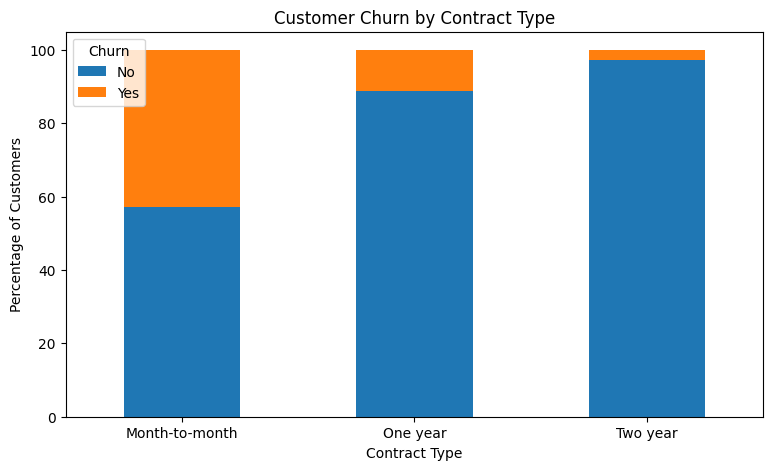

In [51]:
contract_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/churn_by_contract.png",
            dpi=300, bbox_inches="tight")
plt.show()

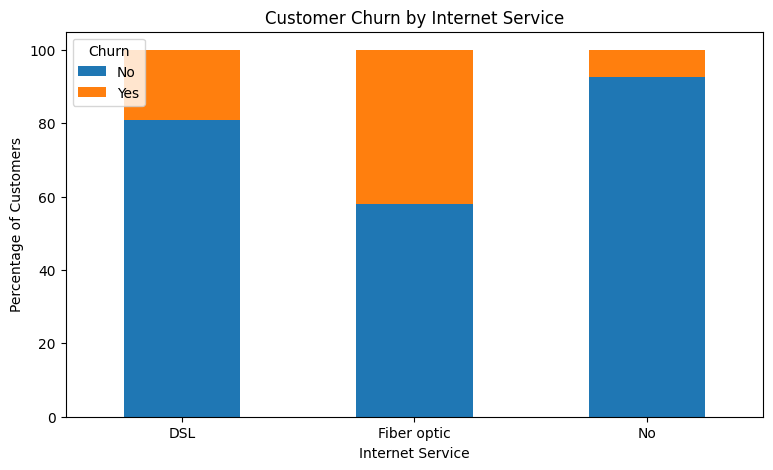

In [52]:
internet_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/churn_by_internet.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [32]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


In [33]:
senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


In [34]:
billing_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

billing_churn

Churn,No,Yes
PaperlessBilling,,
No,83.669916,16.330084
Yes,66.434908,33.565092


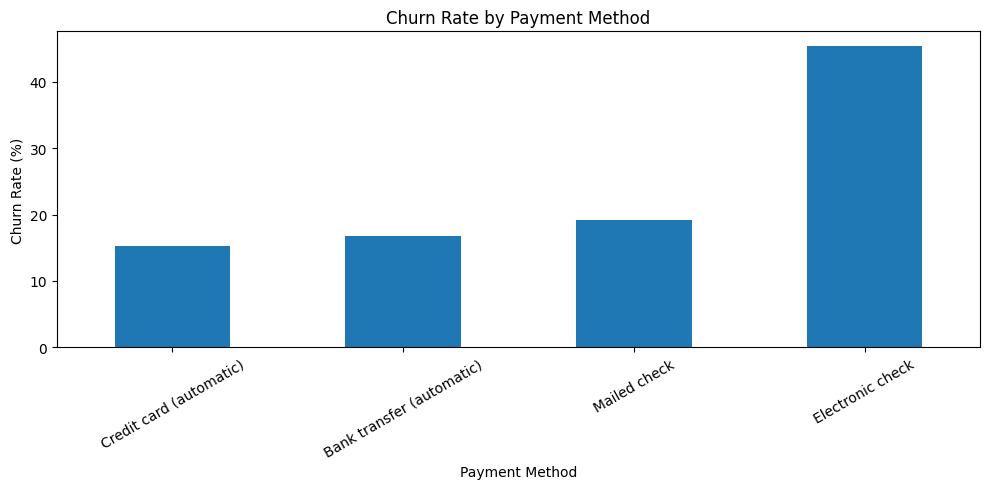

In [53]:
payment_churn['Yes'].sort_values().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/churn_by_payment.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [36]:
# Average tenure by churn
print(df.groupby('Churn')['tenure'].mean())

# Average monthly charges by churn
print(df.groupby('Churn')['MonthlyCharges'].mean())

# Tenure distribution
df.groupby('Churn')['tenure'].describe()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


TenureGroup
0-12 months     2186
13-24 months    1024
25-48 months    1594
49-72 months    2239
Name: count, dtype: int64
Churn                No        Yes
TenureGroup                       
0-12 months   52.561757  47.438243
13-24 months  71.289062  28.710938
25-48 months  79.611041  20.388959
49-72 months  90.486824   9.513176


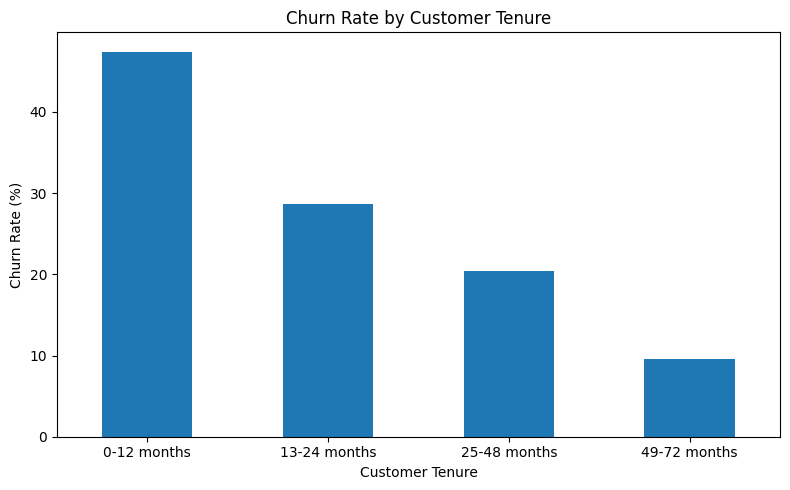

In [54]:
# Create tenure groups
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months',
            '25-48 months', '49-72 months'],
    include_lowest=True
)

# Count customers in each group
print(df['TenureGroup'].value_counts().sort_index())

# Calculate churn percentage in each group
tenure_churn = pd.crosstab(
    df['TenureGroup'],
    df['Churn'],
    normalize='index'
) * 100

print(tenure_churn)

# Visualize churn rates
tenure_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Churn Rate by Customer Tenure')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/churn_by_tenure.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [38]:
# Create readable customer labels
df['CustomerType'] = df['SeniorCitizen'].map({
    0: 'Non-Senior Citizen',
    1: 'Senior Citizen'
})

# Display customer counts
print(df['CustomerType'].value_counts())

CustomerType
Non-Senior Citizen    5901
Senior Citizen        1142
Name: count, dtype: int64


In [39]:
# Churn percentage by tenure and customer type
segment_churn = pd.crosstab(
    [df['TenureGroup'], df['CustomerType']],
    df['Churn'],
    normalize='index'
) * 100

print(segment_churn.round(2))

Churn                               No    Yes
TenureGroup  CustomerType                    
0-12 months  Non-Senior Citizen  56.06  43.94
             Senior Citizen      32.19  67.81
13-24 months Non-Senior Citizen  75.35  24.65
             Senior Citizen      50.60  49.40
25-48 months Non-Senior Citizen  84.08  15.92
             Senior Citizen      58.72  41.28
49-72 months Non-Senior Citizen  91.80   8.20
             Senior Citizen      83.91  16.09


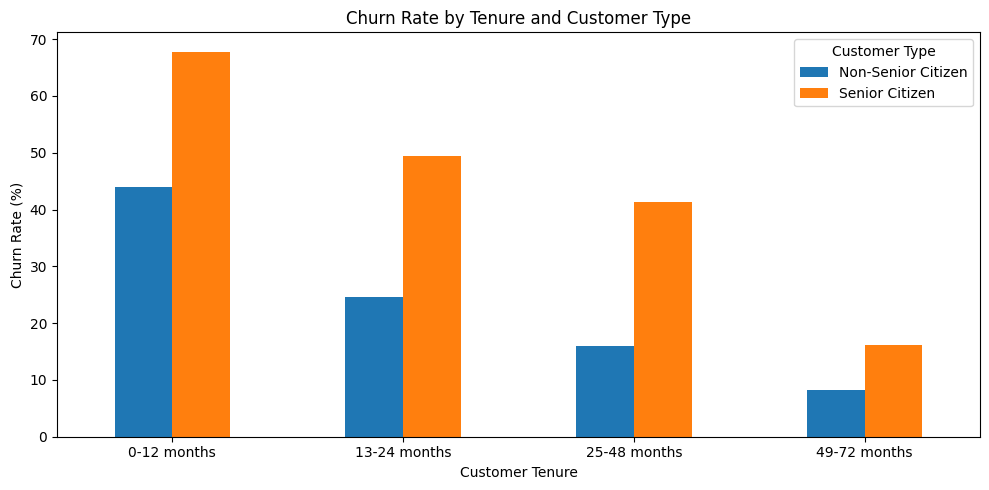

In [55]:
segment_churn['Yes'].unstack().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Churn Rate by Tenure and Customer Type')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.legend(title='Customer Type')
plt.tight_layout()
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/tenure_customer_type.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [41]:
contract_internet = pd.crosstab(
    [df['Contract'], df['InternetService']],
    df['Churn'],
    normalize='index'
) * 100

print(contract_internet.round(2))

Churn                              No    Yes
Contract       InternetService              
Month-to-month DSL              67.78  32.22
               Fiber optic      45.39  54.61
               No               81.11  18.89
One year       DSL              90.70   9.30
               Fiber optic      80.71  19.29
               No               97.53   2.47
Two year       DSL              98.09   1.91
               Fiber optic      92.77   7.23
               No               99.22   0.78


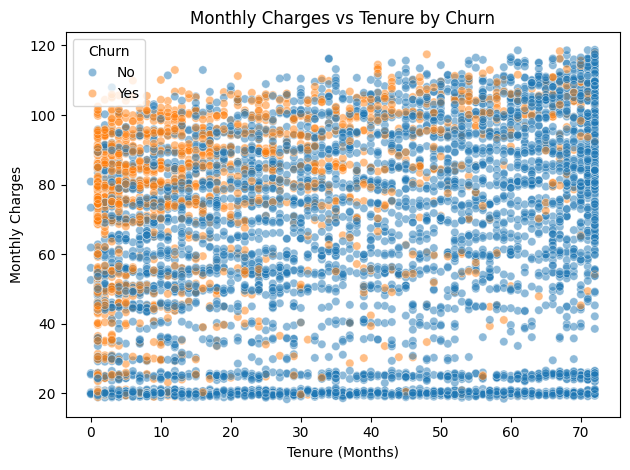

In [56]:
import seaborn as sns

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    hue='Churn',
    alpha=0.5
)

plt.title('Monthly Charges vs Tenure by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Monthly Charges')
plt.tight_layout()
plt.savefig("C:/Users/HP/Documents/customer_churn_analysis/images/charges_vs_tenure.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [47]:
payment_contract = pd.crosstab(
    df['Contract'],
    df['PaymentMethod']
)

print(payment_contract)

PaymentMethod   Bank transfer (automatic)  Credit card (automatic)  \
Contract                                                             
Month-to-month                        589                      543   
One year                              391                      398   
Two year                              564                      581   

PaymentMethod   Electronic check  Mailed check  
Contract                                        
Month-to-month              1850           893  
One year                     347           337  
Two year                     168           382  


In [48]:
risk_customers = df[
    (df['Contract'] == 'Month-to-month') &
    (df['InternetService'] == 'Fiber optic') &
    (df['PaymentMethod'] == 'Electronic check')
]

print("Total customers:", len(risk_customers))

print("\nChurn distribution:")
print(risk_customers['Churn'].value_counts())

print("\nChurn percentage:")
print(
    risk_customers['Churn'].value_counts(normalize=True) * 100
)

Total customers: 1307

Churn distribution:
Churn
Yes    789
No     518
Name: count, dtype: int64

Churn percentage:
Churn
Yes    60.367253
No     39.632747
Name: proportion, dtype: float64


In [50]:
import os

print("Current location:", os.getcwd())
print("Images folder exists:", os.path.exists("C:/Users/HP/Documents/customer_churn_analysis"))

Current location: C:\Users\HP\Documents\customer_churn_analysis\notebook
Images folder exists: True
